# Molecular Biophysics - Particle Diffusion in a Box

Diffusion is a fundamental physical process governing the transport of molecules, ions, and proteins within cellular environments in the absence of external active transport forces. On a microscopic level, this is driven by Brownian motion, where particles undergo a "Random Walk" due to thermal fluctuations and collisions with surrounding molecules.

In a two-dimensional square lattice, the position of each particle is updated at every discrete time step $\Delta t$ by taking a step of length $\Delta x = 1$ in one of four random directions (Up, Down, Left, Right). Microscopically, this random walk is mathematically described by Fick's laws of diffusion. Over time, the mean squared displacement $\langle r^2 \rangle$ of a population of particles increases linearly with time:

$$\langle r^2 \rangle = 4D \cdot t$$

Where $D$ is the diffusion coefficient. In a **Closed Box** of linear dimension $L$, we enforce periodic boundary conditions. This means particles never leave the system; if a particle diffuses past a boundary, it wraps around to the opposite side, maintaining a constant total particle number $N$.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

## Investigating Equilibrium in a Closed Box

To reach equilibrium in a closed system, the macroscopic properties become time-independent. The spatial distribution of particles transitions from highly localized to completely uniform across the box.

### Statistical Metric for Identification
To identify when the system reaches equilibrium, we track the *Spatial Variance ($\sigma^2$)* of the particle coordinates over time. For a completely uniform distribution of particles inside a box of length $L$, the theoretical variance along a given axis is mathematically derived from the uniform probability distribution function:

$$\sigma^2_{theoretical} = \frac{L^2}{12}$$

When the empirical variance of our simulated particle coordinates converges toward this theoretical threshold and stabilizes, the system has reached statistical equilibrium.

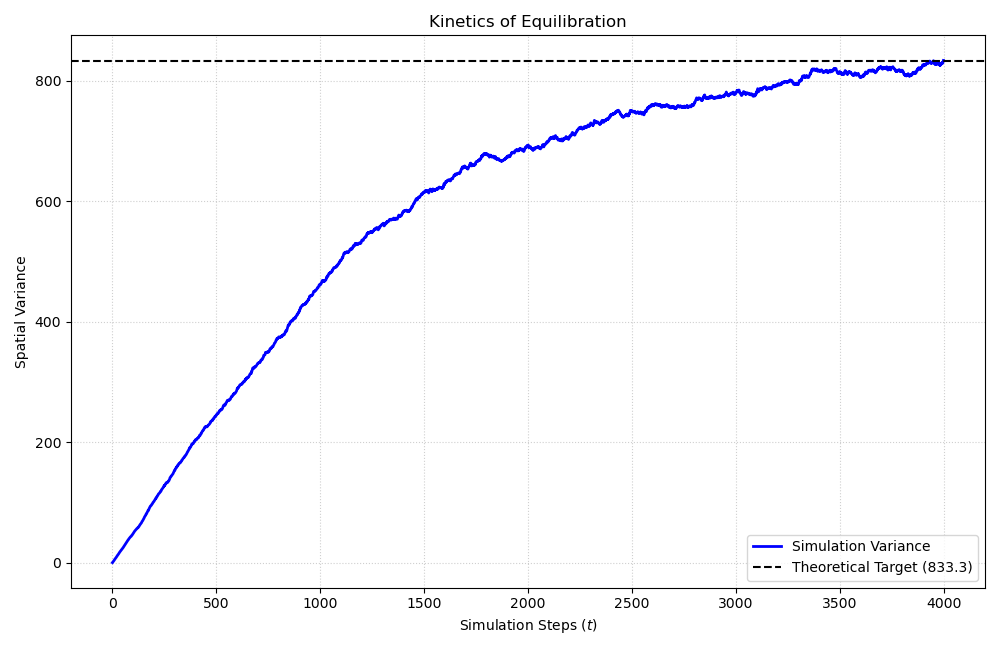

In [1]:
# 1. Define parameters
N = 1000
L = 100
nsteps = 4000

# 2. Start from a point source at the center
coord = np.zeros((N, 3))
coord[:, 0:2] = L / 2

variance_history = []

# 3. Simulation Loop
for step in range(nsteps):
    # Random walk step
    dice = np.random.randint(0, 4, len(coord))
    coord[dice == 0, 0] += 1
    coord[dice == 1, 0] -= 1
    coord[dice == 2, 1] += 1
    coord[dice == 3, 1] -= 1
    
    # Periodic boundary conditions
    coord[coord[:, 0] < 0, 0] += L
    coord[coord[:, 1] < 0, 1] += L
    coord[coord[:, 0] > L, 0] -= L
    coord[coord[:, 1] > L, 1] -= L
    
    # Calculate empirical variance
    v_x = np.var(coord[:, 0])
    v_y = np.var(coord[:, 1])
    variance_history.append((v_x + v_y) / 2)

# 4. Plotting the results
plt.figure(figsize=(10, 6.5))
plt.plot(variance_history, color='blue', linewidth=2, label='Simulation Variance')
plt.axhline(y=(L**2)/12, color='black', linestyle='--', linewidth=1.5, label=f'Theoretical Target ({L**2/12:.1f})')
plt.title('Kinetics of Equilibration', fontsize=12)
plt.xlabel('Simulation Steps ($t$)', fontsize=10)
plt.ylabel('Spatial Variance', fontsize=10)
plt.legend(loc='lower right')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.savefig('closed_box_equilibrium.png', dpi=300)
plt.show()

## Initial Spatial Optimization for Minimal Equilibration Time

### Linear Initialization Function
To analyze how initial spatial configurations influence the kinetics of equilibration, we alter the starting coordinates from a single point source to a continuous central line. The Python function implemented to distribute $N$ particles along a central horizontal line is structured as follows:

```python
def create_in_line(N, L):
    """
    Initializes N particles evenly spaced along a 
    horizontal line across the center of the box.
    """
    coord = np.zeros((N, 3))
    coord[:, 0] = np.linspace(0, L, N)  # Uniform spacing along X
    coord[:, 1] = L / 2                 # Locked at the center of Y
    coord[:, 2] = 0                     # Status flag (free particle)
    return coord

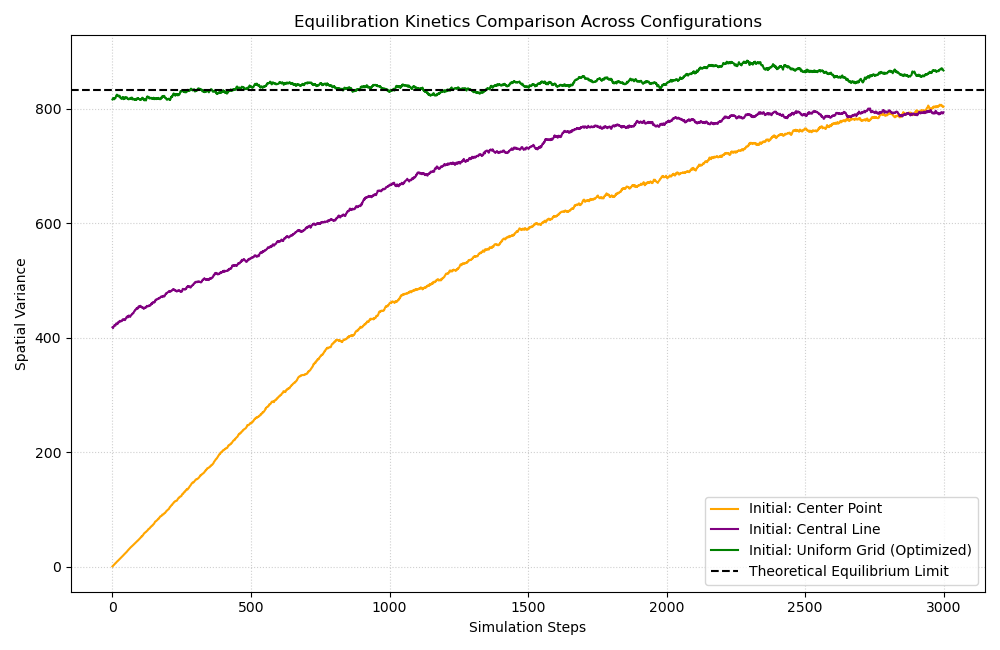

In [2]:
N = 1000
L = 100
nsteps = 3000

def run_sim(init_type):
    if init_type == 'point':
        coord = np.zeros((N, 3))
        coord[:, 0:2] = L / 2
    elif init_type == 'line':
        coord = np.zeros((N, 3))
        coord[:, 0] = np.linspace(0, L, N)
        coord[:, 1] = L / 2
    elif init_type == 'grid':
        coord = np.zeros((N, 3))
        side = int(np.ceil(np.sqrt(N)))
        xs = np.linspace(L/(2*side), L - L/(2*side), side)
        ys = np.linspace(L/(2*side), L - L/(2*side), side)
        X, Y = np.meshgrid(xs, ys)
        flat = np.vstack([X.ravel(), Y.ravel()]).T
        coord[:, 0:2] = flat[:N]
        
    v_hist = []
    for step in range(nsteps):
        dice = np.random.randint(0, 4, len(coord))
        coord[dice == 0, 0] += 1
        coord[dice == 1, 0] -= 1
        coord[dice == 2, 1] += 1
        coord[dice == 3, 1] -= 1
        
        coord[coord[:, 0] < 0, 0] += L
        coord[coord[:, 1] < 0, 1] += L
        coord[coord[:, 0] > L, 0] -= L
        coord[coord[:, 1] > L, 1] -= L
        
        v_hist.append((np.var(coord[:, 0]) + np.var(coord[:, 1])) / 2)
    return v_hist


hist_point = run_sim('point')
hist_line = run_sim('line')
hist_grid = run_sim('grid')


plt.figure(figsize=(10, 6.5))
plt.plot(hist_point, color='orange', label='Initial: Center Point')
plt.plot(hist_line, color='purple', label='Initial: Central Line')
plt.plot(hist_grid, color='green', label='Initial: Uniform Grid (Optimized)')
plt.axhline(y=(L**2)/12, color='black', linestyle='--', label=r'Theoretical Equilibrium Limit')
plt.title(r'Equilibration Kinetics Comparison Across Configurations', fontsize=12)
plt.xlabel('Simulation Steps', fontsize=10)
plt.ylabel(r'Spatial Variance', fontsize=10)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.savefig('comparison_initial_states.png', dpi=300)
plt.show()

## Dynamics of an Open Box / Infinite Pool

In contrast to the Closed Box environment, the **Open Box** (or Infinite Pool) represents an open thermodynamic system that exchanges matter with an external reservoir. The system is governed by two concurrent micro-processes:


1. **Continuous Border Influx:** At every simulation step, new particles are generated along the perimeter of the box to simulate a constant concentration at the boundary.
2. **Efflux via Boundary Checks:** Particles that cross the spatial limit $L$ are permanently removed from the active array using the check function.

### Definition of Open-System Equilibrium (Steady State)
In an open box, equilibrium is not defined by a fixed population spreading out, but rather by the attainment of a **Dynamic Steady State**. This state is reached when the rate of particle influx ($R_{in}$) from the boundaries perfectly matches the rate of stochastic efflux ($R_{out}$). 

Quantitatively, this is identified when the total number of internal particles ($N_{internal}$) stops growing linearly and begins to fluctuate around a constant, time-independent average value.

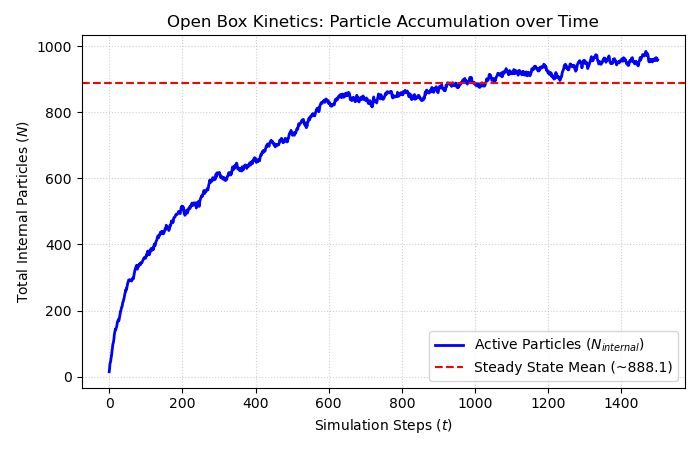

In [3]:
L = 50
nsteps = 1500
coord = np.zeros((0, 3))
particle_counts = []

for step in range(nsteps):
    
    N_border = 20 
    new_particles = np.zeros((N_border, 3))
    perimeter = np.random.randint(0, 4*L, N_border)
    
    new_particles[(perimeter>=0)&(perimeter<L), 0] = perimeter[(perimeter>=0)&(perimeter<L)]
    new_particles[(perimeter>=0)&(perimeter<L), 1] = 0
    
    new_particles[(perimeter>=L)&(perimeter<2*L), 1] = perimeter[(perimeter>=L)&(perimeter<2*L)] - L
    new_particles[(perimeter>=L)&(perimeter<2*L), 0] = 0
    
    new_particles[(perimeter>=2*L)&(perimeter<3*L), 0] = perimeter[(perimeter>=2*L)&(perimeter<3*L)] - 2*L
    new_particles[(perimeter>=2*L)&(perimeter<3*L), 1] = L
    
    new_particles[(perimeter>=3*L)&(perimeter<4*L), 1] = perimeter[(perimeter>=3*L)&(perimeter<4*L)] - 3*L
    new_particles[(perimeter>=3*L)&(perimeter<4*L), 0] = L
    
    if step == 0:
        coord = new_particles
    else:
        coord = np.vstack((coord, new_particles))
        
   
    if len(coord) > 0:
        dice = np.random.randint(0, 4, len(coord))
        coord[dice==0, 0] += 1
        coord[dice==1, 0] -= 1
        coord[dice==2, 1] += 1
        coord[dice==3, 1] -= 1
        
  
    coord = coord[(coord[:, 0] >= 0) & (coord[:, 0] <= L) & (coord[:, 1] >= 0) & (coord[:, 1] <= L)]
    
   
    particle_counts.append(len(coord))


plt.figure(figsize=(7, 4.5))
plt.plot(particle_counts, color='blue', linewidth=2, label='Active Particles ($N_{internal}$)')
stable_mean = np.mean(particle_counts[500:])
plt.axhline(y=stable_mean, color='r', linestyle='--', linewidth=1.5, label=f'Steady State Mean (~{stable_mean:.1f})')
plt.title('Open Box Kinetics: Particle Accumulation over Time', fontsize=12)
plt.xlabel('Simulation Steps ($t$)', fontsize=10)
plt.ylabel('Total Internal Particles ($N$)', fontsize=10)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.savefig('open_box_accumulation.png', dpi=300)
plt.show()

This Figure shows how long it takes for particles to fill the box, depending on where they start. I calculate the spatial variance ($\sigma^2$) at every step. Once this variance hits the theoretical black dashed line ($\sigma^2 = L^2/12 \approx 833.3$), it means the particles are perfectly and evenly distributed across the entire box.

* **Orange Curve:** Since all 1,000 particles begin packed together in the center, the initial variance is zero. As they explode outward, the curve goes up rapidly. It takes the system roughly 1,500 steps to settle into equilibrium. This is our baseline, and it is the slowest approach.
  
* **Purple Curve:** By stretching the particles in a line from left to right at step zero, we effectively pre-solve the spreading problem along the X-axis. Because they are already spread out in one direction, the curve starts halfway up ($\sigma^2 \approx 416.7$) and crosses the finish line much earlier—reaching full equilibrium in just about 500 steps.

* **Green Curve:** In this highly optimized setup, we place the particles at the start. As a result, the system hits the ideal variance threshold at step zero and stays there. The equilibration time is cut down to zero because the system is born in perfect balance.